In [246]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import numpy as np

## import data
resale_1999 = pd.read_csv('../data/Resale Flat Prices (Based on Approval Date), 1990 - 1999.csv')
resale_2000 = pd.read_csv('../data/Resale Flat Prices (Based on Approval Date), 2000 - Feb 2012.csv')
resale_2012 = pd.read_csv('../data/Resale Flat Prices (Based on Registration Date), From Mar 2012 to Dec 2014.csv')
resale_2015 = pd.read_csv('../data/Resale Flat Prices (Based on Registration Date), From Jan 2015 to Dec 2016.csv')
resale_2017 = pd.read_csv('../data/Resale flat prices based on registration date from Jan-2017 onwards.csv')

In [247]:
# inspect data from 2012
print(f"Shape of resale_2012: {resale_2012.shape} \n {'#'*10}")

print(f"Info of resale_2012: \n{resale_2012.info()} \n {'#'*10}")

print(f"Columns of resale_2012: \n{resale_2012.columns} \n {'#'*10}")

resale_2012.head(10)

Shape of resale_2012: (52203, 10) 
 ##########
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52203 entries, 0 to 52202
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   month                52203 non-null  object 
 1   town                 52203 non-null  object 
 2   flat_type            52203 non-null  object 
 3   block                52203 non-null  object 
 4   street_name          52203 non-null  object 
 5   storey_range         52203 non-null  object 
 6   floor_area_sqm       52203 non-null  float64
 7   flat_model           52203 non-null  object 
 8   lease_commence_date  52203 non-null  int64  
 9   resale_price         52203 non-null  float64
dtypes: float64(2), int64(1), object(7)
memory usage: 4.0+ MB
Info of resale_2012: 
None 
 ##########
Columns of resale_2012: 
Index(['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range',
       'floor_area_sqm', 'flat_model', '

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price
0,2012-03,ANG MO KIO,2 ROOM,172,ANG MO KIO AVE 4,06 TO 10,45.0,Improved,1986,250000.0
1,2012-03,ANG MO KIO,2 ROOM,510,ANG MO KIO AVE 8,01 TO 05,44.0,Improved,1980,265000.0
2,2012-03,ANG MO KIO,3 ROOM,610,ANG MO KIO AVE 4,06 TO 10,68.0,New Generation,1980,315000.0
3,2012-03,ANG MO KIO,3 ROOM,474,ANG MO KIO AVE 10,01 TO 05,67.0,New Generation,1984,320000.0
4,2012-03,ANG MO KIO,3 ROOM,604,ANG MO KIO AVE 5,06 TO 10,67.0,New Generation,1980,321000.0
5,2012-03,ANG MO KIO,3 ROOM,154,ANG MO KIO AVE 5,01 TO 05,68.0,New Generation,1981,321000.0
6,2012-03,ANG MO KIO,3 ROOM,110,ANG MO KIO AVE 4,01 TO 05,67.0,New Generation,1978,323000.0
7,2012-03,ANG MO KIO,3 ROOM,445,ANG MO KIO AVE 10,01 TO 05,67.0,New Generation,1979,325000.0
8,2012-03,ANG MO KIO,3 ROOM,476,ANG MO KIO AVE 10,11 TO 15,67.0,New Generation,1979,328000.0
9,2012-03,ANG MO KIO,3 ROOM,631,ANG MO KIO AVE 4,01 TO 05,67.0,New Generation,1985,330000.0


### i) Combine datasets

In [248]:
# concat 2015 on same column names as 2012 only if the columns match

def concat_matching_columns(df1, df2):
    common_columns = df1.columns.intersection(df2.columns)
    
    rows_in_df1 = df1.shape[0]
    rows_in_df2 = df2.shape[0]
    expected_rowcount_after_join = rows_in_df1 + rows_in_df2
    
    concatenated_df = pd.concat([df1[common_columns], df2[common_columns]], ignore_index=True)
    
    # safety check
    actual_rowcount_after_join = concatenated_df.shape[0]
    print(f"Safe: Expected row count: {expected_rowcount_after_join}, Actual row count: {actual_rowcount_after_join}")
    
    assert actual_rowcount_after_join == expected_rowcount_after_join, "Expected and Actual row count mismatch after concat"
    
    return concatenated_df


# Perform concat exercise, check for row count anomalies
def concat_all_raw_datasets(reference_df=resale_2012):
    df_namelist = ['resale_1999', 'resale_2000', 'resale_2015', 'resale_2017']
    raw_df_list = [eval(df) for df in df_namelist]
    
    target_df = pd.DataFrame()
    reference_df = reference_df.copy()
    
    # starts with resale 2012, concats on common columns for rest of dfs.
    target_df = reference_df
    for df in raw_df_list:
        target_df = concat_matching_columns(target_df, df)
    
    return target_df.sort_values(by='month').reset_index(drop=True)

target_df = concat_all_raw_datasets(reference_df=resale_2012).drop_duplicates().reset_index(drop=True)

# rename month to year_month for consistency
target_df = target_df.rename(columns={'month': 'year_month'})

Safe: Expected row count: 339399, Actual row count: 339399
Safe: Expected row count: 709050, Actual row count: 709050
Safe: Expected row count: 746203, Actual row count: 746203
Safe: Expected row count: 988657, Actual row count: 988657


### ii) data profiling

In [249]:
# initial profiling 
print('='*10)
print(target_df.shape)
print('='*10)
print(target_df.info())
print('='*10)
print(target_df.describe())
print('='*10)

(986643, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 986643 entries, 0 to 986642
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year_month           986643 non-null  object 
 1   town                 986643 non-null  object 
 2   flat_type            986643 non-null  object 
 3   block                986643 non-null  object 
 4   street_name          986643 non-null  object 
 5   storey_range         986643 non-null  object 
 6   floor_area_sqm       986643 non-null  float64
 7   flat_model           986643 non-null  object 
 8   lease_commence_date  986643 non-null  int64  
 9   resale_price         986643 non-null  float64
dtypes: float64(2), int64(1), object(7)
memory usage: 75.3+ MB
None
       floor_area_sqm  lease_commence_date  resale_price
count   986643.000000        986643.000000  9.866430e+05
mean        95.697171          1988.911654  3.413726e+05
std         25.711938    

In [250]:
# null value check (measures)
print("----- null value check (measures) -----")

for column in target_df.columns:
    null_count = target_df[column].isnull().sum()
    print(f"{column}: {null_count} null values")

print('\n')
print("----- null value check (attributes) -----")

# null value check (attributes)
for column in target_df.select_dtypes(include=['object']).columns:
    null_count = target_df[column].isnull().sum()
    print(f"{column}: {null_count} null values")

----- null value check (measures) -----
year_month: 0 null values
town: 0 null values
flat_type: 0 null values
block: 0 null values
street_name: 0 null values
storey_range: 0 null values
floor_area_sqm: 0 null values
flat_model: 0 null values
lease_commence_date: 0 null values
resale_price: 0 null values


----- null value check (attributes) -----
year_month: 0 null values
town: 0 null values
flat_type: 0 null values
block: 0 null values
street_name: 0 null values
storey_range: 0 null values
flat_model: 0 null values


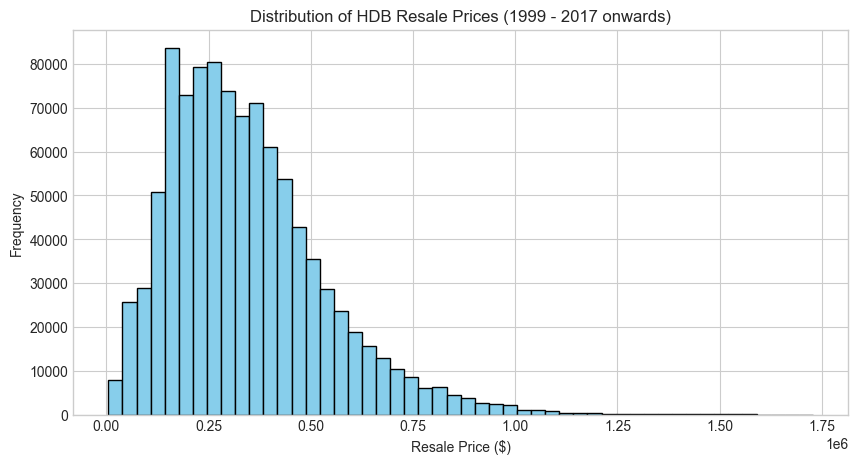

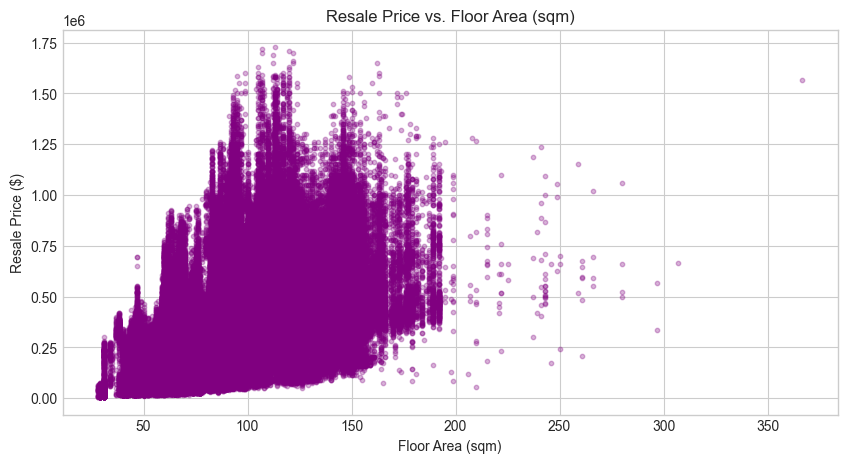

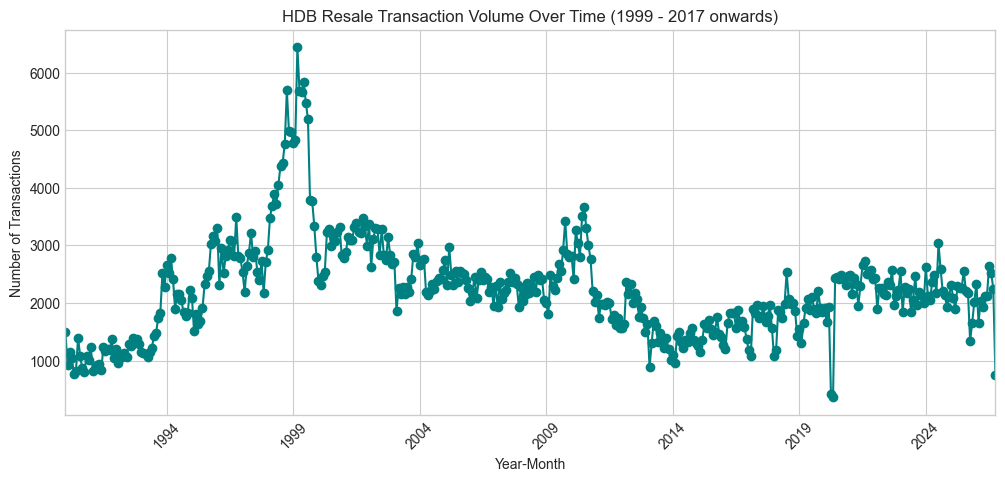

In [251]:
def generate_profiling_charts(df):

  plt.style.use('seaborn-v0_8-whitegrid')

  # 1. Resale Price Distribution
  plt.figure(figsize=(10, 5))
  plt.hist(df['resale_price'], bins=50, color='skyblue', edgecolor='black')
  plt.title('Distribution of HDB Resale Prices (1999 - 2017 onwards)')
  plt.xlabel('Resale Price ($)')
  plt.ylabel('Frequency')
  plt.show()

  # 2. Price vs Floor Area (Scatter Plot)
  plt.figure(figsize=(10, 5))
  plt.scatter(
      df['floor_area_sqm'],
      df['resale_price'],
      alpha=0.3,
      color='purple',
      s=10,
  )
  plt.title('Resale Price vs. Floor Area (sqm)')
  plt.xlabel('Floor Area (sqm)')
  plt.ylabel('Resale Price ($)')
  plt.show()

  # 3. Monthly Transaction Volume Trend
  df['year_month'] = pd.to_datetime(df['year_month']).dt.to_period('M')
  monthly_counts = df.groupby('year_month').size()

  plt.figure(figsize=(12, 5))
  monthly_counts.plot(kind='line', marker='o', color='teal')
  plt.title('HDB Resale Transaction Volume Over Time (1999 - 2017 onwards)')
  plt.xlabel('Year-Month')
  plt.ylabel('Number of Transactions')
  plt.xticks(rotation=45)
  plt.show()
  
generate_profiling_charts(target_df)


In [252]:
# outliers to consider:

# one record with a unusually large floor area
print('Single anomaly for floor_area_sqm: 366.7 sqm')
print(target_df['floor_area_sqm'].sort_values().tail(1))

# transaction spike in mar 1999
print('Transaction spike in march 1999')
print(target_df[target_df['year_month'].dt.year == 1999].groupby('year_month').size().sort_values().tail(5))

Single anomaly for floor_area_sqm: 366.7 sqm
929728    366.7
Name: floor_area_sqm, dtype: float64
Transaction spike in march 1999
year_month
1999-07    5479
1999-05    5655
1999-04    5681
1999-06    5834
1999-03    6439
Freq: M, dtype: int64


### iii) Validate Town, Flat Type, Flat Model, and storey_range using Jan 2012

In [253]:
# jan 2012 golden copy for multi keyset later

jan_2012_df = target_df[target_df['year_month'] == '2012-01'].copy()
print(jan_2012_df.shape)
jan_2012_df.head()

(1559, 10)


,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price
652321,2012-01,SENGKANG,4 ROOM,185B,RIVERVALE CRES,07 TO 09,85.0,Model A2,2000,398000.0
652322,2012-01,SENGKANG,4 ROOM,259B,COMPASSVALE RD,13 TO 15,85.0,Model A2,2001,440000.0
652323,2012-01,SENGKANG,4 ROOM,110,RIVERVALE WALK,04 TO 06,101.0,Model A,1999,443000.0
652324,2012-01,SENGKANG,4 ROOM,117B,RIVERVALE DR,01 TO 03,95.0,Model A,2000,409000.0
652325,2012-01,SENGKANG,4 ROOM,188B,RIVERVALE DR,04 TO 06,96.0,Model A,2000,410000.0


In [254]:
population_df = target_df.copy()
validation_columns = ['town', 'flat_type', 'flat_model', 'storey_range']

jan_2012_reference = jan_2012_df[validation_columns].drop_duplicates().reset_index(drop=True)

def validate_population_against_reference(population_df, reference_df, validation_columns):
    
    validated_master = pd.merge(
        population_df,
        reference_df,
        on=validation_columns,
        how='left',
        indicator=True
    )
    cleaned_master_df = validated_master[validated_master['_merge'] == 'both'].copy().drop(columns=['_merge'])
    quarantined_master_df = validated_master[validated_master['_merge'] == 'left_only'].copy().drop(columns=['_merge'])
    
    print(f"Total Population Records: {population_df.shape[0]}")
    print(f"Total Clean Records: {cleaned_master_df.shape[0]}")
    print(f"Total Quarantined Records: {quarantined_master_df.shape[0]}")
    
    return cleaned_master_df, quarantined_master_df

cleaned_master_df, quarantined_master_df = validate_population_against_reference(population_df, jan_2012_reference, validation_columns)
# the filter is a multi-key filter based on the validation columns

Total Population Records: 986643
Total Clean Records: 509765
Total Quarantined Records: 476878


### iv) Compute remaining lease as of 1 Jan 2027 rounded down to Year and Month

In [255]:
master_df = target_df.copy().drop_duplicates(inplace=False)
master_df['year_month'] = master_df['year_month'].dt.to_timestamp()

def calculate_remaining_lease(reference_date, df):
    
    reference_date = datetime(2027, 1, 1)
    lease_duration_years = 99
    
    df['remaining_lease_days'] = (lease_duration_years * 365) - (reference_date - df['year_month']).dt.days
    
    df['remaining_lease_years'] = df['remaining_lease_days'] // 365
    df['remaining_lease_months'] = (df['remaining_lease_days'] % 365) // 30
    
    return df

reference_date = datetime(2027, 1, 1)


master_df = calculate_remaining_lease(reference_date, master_df)
master_df.head()

,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease_days,remaining_lease_years,remaining_lease_months
0,1990-01-01,KALLANG/WHAMPOA,3 ROOM,34,WHAMPOA WEST,10 TO 12,68.0,IMPROVED,1972,45500.0,22621,61,11
1,1990-01-01,KALLANG/WHAMPOA,3 ROOM,28,JLN BAHAGIA,01 TO 03,56.0,STANDARD,1971,26000.0,22621,61,11
2,1990-01-01,KALLANG/WHAMPOA,3 ROOM,44,BENDEMEER RD,04 TO 06,63.0,STANDARD,1981,31400.0,22621,61,11
3,1990-01-01,KALLANG/WHAMPOA,3 ROOM,20,ST. GEORGE'S RD,04 TO 06,67.0,NEW GENERATION,1984,66500.0,22621,61,11
4,1990-01-01,KALLANG/WHAMPOA,3 ROOM,14,KG ARANG RD,04 TO 06,103.0,NEW GENERATION,1984,77000.0,22621,61,11


### v) Identify anomalous resale prices

In [256]:
master_df = master_df = target_df.copy().drop_duplicates(inplace=False)

def modified_zscore(group):
    median = group.median()
    mad = np.median(np.abs(group - median))

    # edge case: all prices are identical
    if mad == 0:
        return pd.Series(np.zeros_like(group), index=group.index)

    return pd.Series(0.6745 * (group - median) / mad, index=group.index)
    
def anomalous_resale_prices(df, thresh=4):
    
    df['mod_zscore'] = df.groupby(['town', 'flat_type', 'year_month'])['resale_price'].transform(modified_zscore)
    
    df['price_anomaly'] = df['mod_zscore'].abs() > thresh
    
    # quarantine anomalous and normal
    price_anomalies_df = df[df['price_anomaly']].copy()

    valid_priced_df = df[~df['price_anomaly']].copy().drop(columns=['mod_zscore', 'price_anomaly'])

    print(f"total records: {len(df)}")
    print(f"price anomalies: {len(price_anomalies_df)}")
    print(f"valid priced records: {len(valid_priced_df)}")

    return valid_priced_df, price_anomalies_df
    


valid_priced_df, price_anomalies_df = anomalous_resale_prices(master_df, thresh=3)

# used MAD (Median Absolute Deviation) as it measures variance using median which is robust to large outliers
# Modified zscore is prefered over IQR because IQR doesn't account for dispersion within the tails (truncated vs full distribution)
# at thresh 4, we are capturing extreme outliers (outer 0.0063% of the distribution)

total records: 986643
price anomalies: 31687
valid priced records: 954956


# Data Transformation

### viii) create a column called "resale identifier"

In [257]:
master_data_df = target_df.copy()

# rule 1: first character is "S"
first_char = "S"

# rule 2: next 3 digits from block column.
def get_block_digits(df):
    block_digits = df['block'].astype(str) \
        .str.replace(r'\D', '', regex=True) \
        .str.slice(0, 3) \
        .str.zfill(3)
        # get rid of non-digit characters, take first 3 digits, and pad with zeros if necessary
    return block_digits

# rule 3: next 3 digits from first 3 digits of average resale price based on groupings of year-month, town, and flat type.
def get_average_resale_price_digits(df):
    ave_resale_price_digits = df.groupby(['year_month', 'town', 'flat_type'])['resale_price'] \
        .transform('mean') \
        .astype(int) \
        .astype(str) \
        .str.slice(0, 3) \
        .str.zfill(3)
        # take the first 3 digits of the average resale price and pad with zeros if necessary
    return ave_resale_price_digits

# rule 4: next 4 digits are the year_month of the current entry.
def get_year_month_digits(df):
    year_month_digits = df['year_month'].astype(str) \
        .str.replace('-', '', regex=True) \
        .str.slice(2, 6)
        
    return year_month_digits

# rule 5: final character is the first character of the town. 
def get_town_initial(df):
    town_initial = df['town'].astype(str) \
        .str[0] \
        .str.upper()
    return town_initial


master_data_df['resale_identifier_base'] = (
    first_char +
    get_block_digits(master_data_df) +
    get_average_resale_price_digits(master_data_df) +
    get_year_month_digits(master_data_df) +
    get_town_initial(master_data_df)
)

master_data_df['resale_identifier_base']

0         S0344629001K
1         S0284629001K
2         S0444629001K
3         S0204629001K
4         S0144629001K
              ...     
986638    S5247022610T
986639    S5237022610T
986640    S1257832610G
986641    S8697022610T
986642    S6331172610Y
Name: resale_identifier_base, Length: 986643, dtype: object

In [258]:
# rule 6: ensure uniqueness of the identifier

def find_duplicates(df, column):
    identified_duplicates = df[column].value_counts()
    identified_duplicates = identified_duplicates[identified_duplicates > 1]
    print(identified_duplicates)

find_duplicates(master_data_df, 'resale_identifier_base')

# Findings: this is not unique.
    # need to include additional rules to include:
    # bottom floor
    # block characters
    
    
def get_floor_digits(df):
    floor_digits = df['storey_range'].str.replace(r'(\d+)\s+TO\s+(\d+)', r'\1\2', regex=True)
    return floor_digits

def get_block_chars(df):
    block_chars = df['block'].str \
        .replace(r'[^A-Za-z0-9]', '', regex=True)
    return block_chars

test_df = target_df.copy()
test_df['resale_identifier_base'] = (
    first_char +
    get_block_digits(master_data_df) +
    get_average_resale_price_digits(master_data_df) +
    get_year_month_digits(master_data_df) +
    get_floor_digits(master_data_df) +
    get_block_chars(master_data_df) +
    get_town_initial(master_data_df)
)


resale_identifier_base
S8564619904T    37
S8564519905T    28
S8423589904T    27
S8423549905T    25
S2892310301B    23
                ..
S1832229303B     2
S0572439607M     2
S1704039612B     2
S0633089612B     2
S1783109601W     2
Name: count, Length: 148686, dtype: int64


In [259]:
print(find_duplicates(test_df, 'resale_identifier_base'))
test_df[test_df.duplicated('resale_identifier_base', keep=False)].sort_values(
    'resale_identifier_base').head(10)

# I don't want to include resale_price as a identifier, changing approach to indexing duplicates and including it as a identifier

resale_identifier_base
S0111139708010311K      9
S19237398100406192P     8
S0101139708010310K      8
S005175090101035P       7
S30964899120406309A     7
                       ..
S61627499110103616C     2
S75743799070103757C     2
S0661669105101266B      2
S12718799050103127W     2
S16655725060406166AJ    2
Name: count, Length: 43484, dtype: int64
None


,year_month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,resale_identifier_base
85889,1995-01,BUKIT MERAH,3 ROOM,1,EVERTON PK,07 TO 09,72.0,NEW GENERATION,1980,105000.0,S001103950107091B
85890,1995-01,BUKIT MERAH,3 ROOM,1,EVERTON PK,07 TO 09,82.0,NEW GENERATION,1980,90000.0,S001103950107091B
184082,1998-02,GEYLANG,2 ROOM,1,JLN PASAR BARU,07 TO 09,41.0,STANDARD,1971,123000.0,S001103980207091G
184081,1998-02,GEYLANG,2 ROOM,1,JLN PASAR BARU,07 TO 09,41.0,STANDARD,1971,101000.0,S001103980207091G
184080,1998-02,GEYLANG,2 ROOM,1,JLN PASAR BARU,07 TO 09,40.0,STANDARD,1971,118000.0,S001103980207091G
158910,1997-05,GEYLANG,2 ROOM,1,JLN PASAR BARU,04 TO 06,41.0,STANDARD,1971,120000.0,S001111970504061G
158911,1997-05,GEYLANG,2 ROOM,1,JLN PASAR BARU,04 TO 06,40.0,STANDARD,1971,138000.0,S001111970504061G
158884,1997-05,GEYLANG,2 ROOM,1,JLN PASAR BARU,04 TO 06,41.0,STANDARD,1971,95000.0,S001111970504061G
169736,1997-09,GEYLANG,2 ROOM,1,JLN PASAR BARU,01 TO 03,41.0,STANDARD,1971,125000.0,S001115970901031G
169738,1997-09,GEYLANG,2 ROOM,1,JLN PASAR BARU,01 TO 03,41.0,STANDARD,1971,105000.0,S001115970901031G


In [260]:
# improved approach - we number each sequence and include it as a key before the last character

def get_sequence_digits(df):
    seq_series = df.groupby('resale_identifier_base').cumcount()
    
    # 3 digit padding
    seq_series = seq_series.apply(lambda x: f"{x:03d}")
    
    return seq_series

master_data_df['resale_identifier_base'] = (
    master_data_df['resale_identifier_base'].str.slice(0, -1) +
    get_sequence_digits(master_data_df) +
    master_data_df['resale_identifier_base'].str.slice(-1)
)


print(find_duplicates(master_data_df, 'resale_identifier_base'))

# no duplicates detected.

Series([], Name: count, dtype: int64)
None


### ix) De-identify the identifier column using an irreversible algorithm

In [270]:
# approach - we can use a cryptographic hash function to de-identify the identifier column irreversibly. Something like SHA-256 which serves
    # as a mathematical one-way function.
    # append a secret string before hashing to prevent pre-computed dictionary attacks
    
import hashlib
import os

hashed_master_df = master_data_df.copy()
secret_hash = os.environ.get('SECRET_HASH', 'default_secret')

def generate_hash(identifier, secret):
    
    combined = f"{identifier}{secret}"
    return hashlib.sha256(combined.encode('utf-8')).hexdigest()


hashed_master_df['hashed_resale_identifier'] = (
    hashed_master_df['resale_identifier_base'].apply(lambda x: generate_hash(x, secret_hash))
)


def verify_hash():
    original_unique = master_data_df['resale_identifier_base'].nunique()
    hashed_unique = hashed_master_df['hashed_resale_identifier'].nunique()

    print(f"Total records: {len(hashed_master_df)}")
    print(f"Original unique identifiers: {original_unique}")
    print(f"Hashed unique identifiers: {hashed_unique}")
    print(f"Uniqueness preserved: {original_unique == hashed_unique}")


    print("\Compare Hashed Identifiers:")
    print(hashed_master_df[['resale_identifier_base',
          'hashed_resale_identifier']].head(5))


verify_hash()

Total records: 986643
Original unique identifiers: 986643
Hashed unique identifiers: 986643
Uniqueness preserved: True

Sample Hashed Identifiers:
  resale_identifier_base                           hashed_resale_identifier
0        S0344629001000K  1d1b1baac740c30197fba7a7042582de70a3be1b84631d...
1        S0284629001000K  279ba238db404b604d18673307e3d00ca93eb691fe7fe9...
2        S0444629001000K  818dfa0542677f9310d3a97f420fc634f403714ae4763b...
3        S0204629001000K  7d8a1d5916fea8c36d7c7f58e59e123254962cdf92f5e0...
4        S0144629001000K  dd60d28f307df96defdaad18ceb7ec73ab10ea1f127e86...
